# 01 Monte Carlo：随机入口状态与海流

方法与参数沿用 `GNSS_Bridge_Same_Bridge.ipynb`，代码在 `bridge_sim/core.py`（原样拷贝，未改动）。
`bridge_sim/ext.py` 中的 `run_case_ext` 在默认参数下与原 `run_case` 逐位一致（见 `tests/test_regression.py`）。
所有运行使用同一组误差界参数，不按案例调整。

**随机化（全部落在声明误差界内，即 A1–A2 成立）**

| 量 | 分布 | 声明界 |
|---|---|---|
| 已知背景流 北/东 | U[0, 0.05] / U[0.03, 0.12] m/s | 已知，进入制导 |
| 已知射流幅值 | U[0.15, 0.35] m/s | 已知 |
| 真实射流幅值误差 | U[−0.20, 0.20] m/s | 0.22 |
| 背景流偏置 北/东 | U[−0.008, 0.008] / U[−0.010, 0.010] m/s | 0.010 / 0.015（东向含潮汐 ≤ 0.004） |
| 潮汐幅值/频率 | U[0, 0.004] m/s, U[0.02, 0.08] rad/s | |
| 桥墙配准误差 | U[−0.06, 0.06] m | 0.08 |
| 入口横向偏差 / 艏向误差 | U[−0.5, 0.5] m / U[−0.10, 0.10] rad | |
| 陀螺零偏 | U[−0.00055, 0.00055] rad/s（另加 ±0.00025 噪声） | 0.0008 |
| 传感器随机种子 | 每个场景不同 | |

**两部分**：A 为主实验桥（8 m × 19 m），B 为桥长随机 U[15, 50] m（宽 8 m），让场景有易有难。

**事后“能过”标注（oracle）**：同一世界、同一进近，入口处直接切换到 14 个候选航速之一、全程无滤波 ILOS；
只要有一个航速以真实船体间隙 > 0 通过，就记为“能过”。被评估方法自己无碰撞通过的也记为能过。
另给出更严格口径：间隙 ≥ 0.10 m（方法自身预留的海图配准 0.08 + 采样保护 0.02）。

**指标**
- 错误放行率：放行后撞墙的比例（按放行数）；另报放行但事后不能过的比例。
- 误拒率：事后能过却被拒绝的比例（按能过数）。
- 通过率：无碰撞完成过桥的比例（按全部场景）。
- 误差界覆盖率：全程真实北/东/艏向导航误差都在误差界内的场景比例。
- 认证丢失率：放行后桥下某一步找不到通过验证的动作（`no verified action`）的比例（按放行数），是 A3 的经验检验。
- 比例都给 95% Wilson 区间；0/N 的上界即“三分之一法则”。

In [1]:
import sys, time, json
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from bridge_sim.ext import sample_scenario, run_batch, DEFAULT_SCENARIO, evaluate
from bridge_sim.metrics import rates_table, ilos_rates, fmt_table, feasible, covered, METHOD_BUDGET

RES = ROOT/'results'; RES.mkdir(exist_ok=True)
FIG = ROOT/'figures'; FIG.mkdir(exist_ok=True)
WORKERS = 4
N_MAIN, N_RAND = 200, 240
METHODS = ('filter', 'ilos07', 'oracle')
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 60)

def main_scenarios():
    rng = np.random.default_rng(2026)
    return [sample_scenario(rng, 10000 + i, length=19.0, width=8.0) for i in range(N_MAIN)]

def random_length_scenarios():
    rng = np.random.default_rng(2027)
    out = []
    for i in range(N_RAND):
        L = float(rng.uniform(15.0, 50.0))
        out.append(sample_scenario(rng, 20000 + i, length=round(L, 2), width=8.0))
    return out

def cached(path, scenarios, methods, **kw):
    if path.exists():
        print('loading', path.name)
        return pd.read_csv(path)
    t0 = time.time()
    df = pd.DataFrame(run_batch(scenarios, methods, workers=WORKERS, log_path=str(RES/'progress.log'), **kw))
    df.to_csv(path, index=False)
    print(f'{path.name}: {len(df)} scenarios in {time.time()-t0:.0f} s')
    return df

## A. 主实验桥 8 m × 19 m

In [2]:
mc_main = cached(RES/'mc_main_bridge.csv', main_scenarios(), METHODS)
assert 'error' not in mc_main or mc_main['error'].isna().all()
tabA = pd.concat([rates_table(mc_main, ['filter'], 0.0), rates_table(mc_main, ['filter'], METHOD_BUDGET),
                  ilos_rates(mc_main)])
tabA.insert(0, 'part', 'A: 8x19 m')
fmt_table(tabA)

loading mc_main_bridge.csv


,part,method,metric,threshold_m,rate,95% CI,k/n
0,A: 8x19 m,filter,accept (放行率),0.0,100.0%,"[98.1, 100.0]%",200/200
1,A: 8x19 m,filter,pass (通过率),0.0,100.0%,"[98.1, 100.0]%",200/200
2,A: 8x19 m,filter,collision (撞墙率),0.0,0.0%,"[0.0, 1.9]%",0/200
3,A: 8x19 m,filter,"false accept: admitted & collided (错误放行, 按放行数)",0.0,0.0%,"[0.0, 1.9]%",0/200
4,A: 8x19 m,filter,"false accept: admitted & infeasible (错误放行, 按放行数)",0.0,0.0%,"[0.0, 1.9]%",0/200
5,A: 8x19 m,filter,"false reject (误拒, 按能过数)",0.0,0.0%,"[0.0, 1.9]%",0/200
6,A: 8x19 m,filter,"bound coverage (误差界覆盖率, 全程)",0.0,100.0%,"[98.1, 100.0]%",200/200
7,A: 8x19 m,filter,"certification loss (认证丢失, 按放行数)",0.0,0.0%,"[0.0, 1.9]%",0/200
8,A: 8x19 m,filter,feasible (能过比例),0.0,100.0%,"[98.1, 100.0]%",200/200
0,A: 8x19 m,filter,accept (放行率),0.1,100.0%,"[98.1, 100.0]%",200/200


## B. 随机桥长 U[15, 50] m，宽 8 m

In [3]:
mc_rand = cached(RES/'mc_random_length.csv', random_length_scenarios(), METHODS)
assert 'error' not in mc_rand or mc_rand['error'].isna().all()
tabB = pd.concat([rates_table(mc_rand, ['filter'], 0.0), rates_table(mc_rand, ['filter'], METHOD_BUDGET),
                  ilos_rates(mc_rand)])
tabB.insert(0, 'part', 'B: 8 m, L~U[15,50]')
summary = pd.concat([tabA, tabB], ignore_index=True)
summary.to_csv(RES/'mc_summary.csv', index=False)
fmt_table(tabB)

loading mc_random_length.csv


,part,method,metric,threshold_m,rate,95% CI,k/n
0,"B: 8 m, L~U[15,50]",filter,accept (放行率),0.0,17.9%,"[13.6, 23.3]%",43/240
1,"B: 8 m, L~U[15,50]",filter,pass (通过率),0.0,17.9%,"[13.6, 23.3]%",43/240
2,"B: 8 m, L~U[15,50]",filter,collision (撞墙率),0.0,0.0%,"[0.0, 1.6]%",0/240
3,"B: 8 m, L~U[15,50]",filter,"false accept: admitted & collided (错误放行, 按放行数)",0.0,0.0%,"[0.0, 8.2]%",0/43
4,"B: 8 m, L~U[15,50]",filter,"false accept: admitted & infeasible (错误放行, 按放行数)",0.0,0.0%,"[0.0, 8.2]%",0/43
5,"B: 8 m, L~U[15,50]",filter,"false reject (误拒, 按能过数)",0.0,81.9%,"[76.5, 86.2]%",194/237
6,"B: 8 m, L~U[15,50]",filter,"bound coverage (误差界覆盖率, 全程)",0.0,100.0%,"[98.4, 100.0]%",240/240
7,"B: 8 m, L~U[15,50]",filter,"certification loss (认证丢失, 按放行数)",0.0,0.0%,"[0.0, 8.2]%",0/43
8,"B: 8 m, L~U[15,50]",filter,feasible (能过比例),0.0,98.8%,"[96.4, 99.6]%",237/240
0,"B: 8 m, L~U[15,50]",filter,accept (放行率),0.1,17.9%,"[13.6, 23.3]%",43/240


### 场景分布与关键数字

In [4]:
for name, df in (('A', mc_main), ('B', mc_rand)):
    adm = df['filter_admitted'].fillna(False).astype(bool)
    print(f"[{name}] N={len(df)}  admitted={adm.sum()}  selected speeds:",
          df.loc[adm, 'filter_transit_speed'].value_counts().sort_index().to_dict())
    print(f"     filter min clearance (admitted): min {df.loc[adm,'filter_min_clearance'].min():.3f} m, "
          f"median {df.loc[adm,'filter_min_clearance'].median():.3f} m")
    print(f"     max |err|/bound over all runs: N {df['filter_cov_ratio_N'].max():.3f}, "
          f"E {df['filter_cov_ratio_E'].max():.3f}, heading {df['filter_cov_ratio_heading'].max():.3f}")
    print(f"     oracle feasible: {feasible(df,'filter').mean():.3f};  ILOS 0.7 collisions: {df['ilos07_collided'].sum()}")

[A] N=200  admitted=200  selected speeds: {1.6: 194, 1.8: 6}
     filter min clearance (admitted): min 1.339 m, median 2.421 m
     max |err|/bound over all runs: N 0.972, E 0.987, heading 0.997
     oracle feasible: 1.000;  ILOS 0.7 collisions: 17
[B] N=240  admitted=43  selected speeds: {1.5: 12, 1.6: 8, 1.7: 9, 1.8: 11, 1.9: 3}
     filter min clearance (admitted): min 1.269 m, median 2.410 m
     max |err|/bound over all runs: N 0.999, E 0.997, heading 0.994
     oracle feasible: 0.988;  ILOS 0.7 collisions: 93


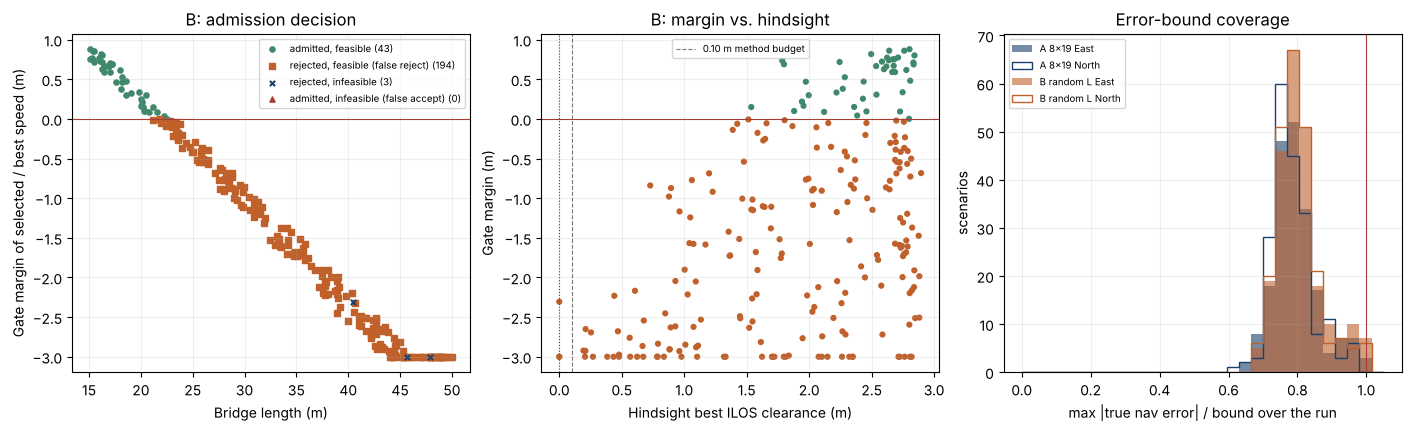

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), layout='constrained')
df = mc_rand
adm = df['filter_admitted'].fillna(False).astype(bool)
feas = feasible(df, 'filter')
ax = axes[0]
for mask, lab, col, mk in ((adm & feas, 'admitted, feasible', '#40886c', 'o'),
                           (~adm & feas, 'rejected, feasible (false reject)', '#c0612b', 's'),
                           (~adm & ~feas, 'rejected, infeasible', '#1b3f6b', 'x'),
                           (adm & ~feas, 'admitted, infeasible (false accept)', '#a83b34', '^')):
    m = np.clip(df.loc[mask, 'filter_entry_margin'].replace(-np.inf, np.nan), -3, None)
    ax.scatter(df.loc[mask, 'length'], m, s=14, c=col, marker=mk, label=f'{lab} ({mask.sum()})')
ax.axhline(0, color='#a83b34', lw=.8)
ax.set(xlabel='Bridge length (m)', ylabel='Gate margin of selected / best speed (m)', title='B: admission decision')
ax.legend(fontsize=7); ax.grid(alpha=.2)

ax = axes[1]
ax.scatter(df['oracle_best_clearance'], np.clip(df['filter_entry_margin'].replace(-np.inf, np.nan), -3, None),
           s=12, c=np.where(adm, '#40886c', '#c0612b'))
ax.axhline(0, color='#a83b34', lw=.8); ax.axvline(0, color='#444', lw=.8, ls=':')
ax.axvline(METHOD_BUDGET, color='#777', lw=.8, ls='--', label='0.10 m method budget')
ax.set(xlabel='Hindsight best ILOS clearance (m)', ylabel='Gate margin (m)', title='B: margin vs. hindsight')
ax.legend(fontsize=7); ax.grid(alpha=.2)

ax = axes[2]
for name, d, col in (('A 8x19', mc_main, '#1b3f6b'), ('B random L', mc_rand, '#c0612b')):
    ax.hist(d['filter_cov_ratio_E'], bins=30, range=(0, 1.05), alpha=.6, color=col, label=f'{name} East')
    ax.hist(d['filter_cov_ratio_N'], bins=30, range=(0, 1.05), histtype='step', color=col, label=f'{name} North')
ax.axvline(1, color='#a83b34', lw=.8)
ax.set(xlabel='max |true nav error| / bound over the run', ylabel='scenarios', title='Error-bound coverage')
ax.legend(fontsize=7); ax.grid(alpha=.2)
fig.savefig(FIG/'mc_overview.png', dpi=200); fig.savefig(FIG/'mc_overview.pdf')
plt.show()

In [6]:
# B by length bin: what fraction is feasible / admitted / passed
bins = np.arange(15, 51, 5)
g = mc_rand.assign(bin=pd.cut(mc_rand['length'], bins, include_lowest=True),
                   feasible=feasible(mc_rand, 'filter'),
                   admitted=mc_rand['filter_admitted'].fillna(False).astype(bool),
                   passed=mc_rand['filter_completed'] & ~mc_rand['filter_collided'],
                   ilos_ok=~mc_rand['ilos07_collided'])
byL = g.groupby('bin', observed=True)[['feasible', 'admitted', 'passed', 'ilos_ok']].mean()
byL['n'] = g.groupby('bin', observed=True).size()
byL.round(3)

,feasible,admitted,passed,ilos_ok,n
bin,,,,,
"(14.999, 20.0]",1.000,1.000,1.000,1.000,31
"(20.0, 25.0]",1.000,0.364,0.364,0.667,33
"(25.0, 30.0]",1.000,0.000,0.000,0.789,38
"(30.0, 35.0]",1.000,0.000,0.000,0.515,33
"(35.0, 40.0]",1.000,0.000,0.000,0.594,32
"(40.0, 45.0]",0.975,0.000,0.000,0.375,40
"(45.0, 50.0]",0.939,0.000,0.000,0.394,33


## 结论

数字取自上面的实际运行（统一参数）。
**安全性**
- A 部分（8 m × 19 m，200 个世界）：放行 200/200，通过 200/200，撞墙 0/200（95% 上界 1.9%）。同一批世界里，0.7 m/s 名义 ILOS 撞墙 17/200（8.5%）。
- B 部分（桥长 15–50 m，240 个世界）：放行 43/240，放行后撞墙 0/43；全部场景撞墙 0/240（上界 1.6%）。同一批世界里 ILOS 撞墙 93/240（38.8%）。
- 误差界覆盖率 100%（440/440），认证丢失 0。断星段真实东向误差最多为误差界的 0.68 倍，中位数约 0.40 倍。全程最大比值约 0.99～1.00，出现在 GNSS 可用的进近段，那里误差界本身很小。
- 放行场景的最小真实间隙：A 部分 1.34 m，B 部分 1.27 m。

**保守性（结果不好）**
- B 部分误拒率 81.9%（194/237）。事后 oracle 几乎全部“能过”（237/240），而方法只放行约 23 m 以内的桥：20–25 m 放行 36%，25 m 以上为 0。按 0.10 m 间隙口径，误拒率相同。
- 原因 1：oracle 是事后、非因果的参照，它知道本次世界的真实海流，并从 14 个航速里挑最好的。随机世界的射流误差平均只有声明界的一半，而误差界必须对所有允许的世界都成立。
- 原因 2：误差界对随机世界偏松，断星段真实误差最多只用到界的 68%。最坏世界下误差界的松紧见 02 第三部分和 04。

**A 部分的局限**：主实验桥在随机世界里太容易，误拒和错误放行都测不出来，只能说明“不拒能过的主桥，也不出事”。